In [1]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu a) Đọc bộ dữ liệu train, test của MNIST từ Keras
import os
os.environ['KERAS_BACKEND'] = 'torch'
import keras
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Đọc bộ dữ liệu MNIST từ Keras
(train_images, train_labels), (test_images, test_labels) = keras.datasets.mnist.load_data()
print("Đã tải thành công bộ dữ liệu MNIST từ thư viện Keras!")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Đã tải thành công bộ dữ liệu MNIST từ thư viện Keras!


In [3]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu b) In ra kích thước của tập train, test
print(f"Kích thước tập ảnh train (train_images.shape): {train_images.shape}")
print(f"Kích thước tập nhãn train (train_labels.shape): {train_labels.shape}")
print(f"Kích thước tập ảnh test (test_images.shape):   {test_images.shape}")
print(f"Kích thước tập nhãn test (test_labels.shape):   {test_labels.shape}")
print(f"Mỗi ảnh có kích thước: {train_images.shape[1]}x{train_images.shape[2]} pixel, giá trị pixel từ 0 đến 255.")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Kích thước tập ảnh train (train_images.shape): (60000, 28, 28)
Kích thước tập nhãn train (train_labels.shape): (60000,)
Kích thước tập ảnh test (test_images.shape):   (10000, 28, 28)
Kích thước tập nhãn test (test_labels.shape):   (10000,)
Mỗi ảnh có kích thước: 28x28 pixel, giá trị pixel từ 0 đến 255.


In [5]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu c) Chuẩn hóa các giá trị pixel của ảnh về đoạn [0,1]
# Chia cho 255.0
train_images = train_images / 255.0
test_images = test_images / 255.0

print(f"Giá trị pixel nhỏ nhất sau chuẩn hóa: {train_images.min():.1f}")
print(f"Giá trị pixel lớn nhất sau chuẩn hóa: {train_images.max():.1f}")
print("Đã chuẩn hóa toàn bộ pixel về đoạn [0, 1] thành công!")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Giá trị pixel nhỏ nhất sau chuẩn hóa: 0.0
Giá trị pixel lớn nhất sau chuẩn hóa: 1.0
Đã chuẩn hóa toàn bộ pixel về đoạn [0, 1] thành công!


In [6]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu d) Chia tập train ban đầu thành tập train và tập validation theo tỷ lệ 8:2
from sklearn.model_selection import train_test_split

train_images, val_images, train_labels, val_labels = train_test_split(
    train_images, train_labels, test_size=0.2, random_state=42
)

print(f"Kích thước tập train mới:       {train_images.shape}, nhãn: {train_labels.shape}")
print(f"Kích thước tập validation:     {val_images.shape}, nhãn: {val_labels.shape}")
print(f"Kích thước tập test:           {test_images.shape}, nhãn: {test_labels.shape}")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Kích thước tập train mới:       (48000, 28, 28), nhãn: (48000,)
Kích thước tập validation:     (12000, 28, 28), nhãn: (12000,)
Kích thước tập test:           (10000, 28, 28), nhãn: (10000,)


In [7]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu e) Xây dựng Neural Network gồm các layers theo yêu cầu
from keras.models import Sequential
from keras.layers import Flatten, Dense, Dropout, Input

model = Sequential([
    Input(shape=(28, 28)),
    Flatten(),                        # Làm phẳng 28x28 thành vector 784 chiều
    Dense(128, activation='relu'),     # 128 nơ-ron, hàm kích hoạt Relu
    Dropout(0.2),                     # Tắt ngẫu nhiên 20% nơ-ron chống overfitting
    Dense(10, activation='softmax')   # 10 nơ-ron đại diện 10 chữ số (0-9), Softmax
])

model.summary()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu f) Biên dịch mô hình
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
print("Đã biên dịch mô hình với optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']!")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Đã biên dịch mô hình với optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']!


In [9]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu g) Huấn luyện mô hình dựa trên tập train, đánh giá với tập validation
# epoch: 5; batch_size: 32
history = model.fit(
    train_images, train_labels,
    epochs=5,
    batch_size=32,
    validation_data=(val_images, val_labels),
    verbose=1
)


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Epoch 1/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9062 - loss: 0.3241 - val_accuracy: 0.9542 - val_loss: 0.1605
Epoch 2/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9529 - loss: 0.1605 - val_accuracy: 0.9657 - val_loss: 0.1189
Epoch 3/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9650 - loss: 0.1190 - val_accuracy: 0.9700 - val_loss: 0.0996
Epoch 4/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - accuracy: 0.9695 - loss: 0.0957 - val_accuracy: 0.9745 - val_loss: 0.0856
Epoch 5/5
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.9748 - loss: 0.0808 - val_accuracy: 0.9743 - val_loss: 0.0831


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


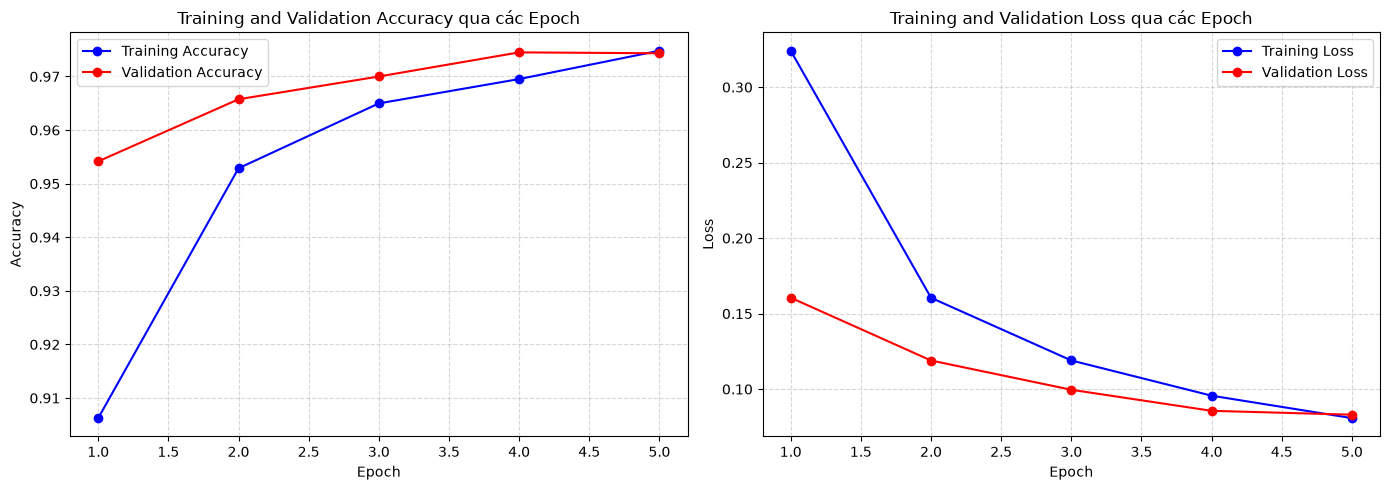

In [10]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu h) Vẽ biểu đồ thể hiện accuracy, loss sau mỗi epoch
plt.figure(figsize=(14, 5))

# Biểu đồ Accuracy
plt.subplot(1, 2, 1)
plt.plot(range(1, 6), history.history['accuracy'], 'bo-', label='Training Accuracy')
plt.plot(range(1, 6), history.history['val_accuracy'], 'ro-', label='Validation Accuracy')
plt.title('Training and Validation Accuracy qua các Epoch')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

# Biểu đồ Loss
plt.subplot(1, 2, 2)
plt.plot(range(1, 6), history.history['loss'], 'bo-', label='Training Loss')
plt.plot(range(1, 6), history.history['val_loss'], 'ro-', label='Validation Loss')
plt.title('Training and Validation Loss qua các Epoch')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()

plt.tight_layout()
plt.show()


In [11]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu i) Dự đoán phân lớp cho tập test
y_prob = model.predict(test_images)
y_pred = np.argmax(y_prob, axis=1)

print(f"Kích thước ma trận xác suất dự đoán (y_prob.shape): {y_prob.shape}")
print(f"10 nhãn dự đoán đầu tiên: {y_pred[:10]}")
print(f"10 nhãn thực tế đầu tiên: {test_labels[:10]}")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step
Kích thước ma trận xác suất dự đoán (y_prob.shape): (10000, 10)
10 nhãn dự đoán đầu tiên: [7 2 1 0 4 1 4 9 6 9]
10 nhãn thực tế đầu tiên: [7 2 1 0 4 1 4 9 5 9]


In [12]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu j) Tính và in ra Accuracy của mô hình trên tập test
from sklearn.metrics import accuracy_score

test_acc = accuracy_score(test_labels, y_pred)
print(f"Accuracy của Neural Network trên tập test: {test_acc * 100:.2f}%")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Accuracy của Neural Network trên tập test: 97.53%


In [13]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu k) Tính và in ra Precision, Recall, F1-score của từng lớp và trung bình
from sklearn.metrics import classification_report

target_names = [f"Chữ số {i}" for i in range(10)]
print("--- Classification Report trên tập Test MNIST ---")
print(classification_report(test_labels, y_pred, target_names=target_names))


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
--- Classification Report trên tập Test MNIST ---
              precision    recall  f1-score   support

    Chữ số 0       0.97      0.99      0.98       980
    Chữ số 1       0.99      0.99      0.99      1135
    Chữ số 2       0.96      0.98      0.97      1032
    Chữ số 3       0.97      0.97      0.97      1010
    Chữ số 4       0.98      0.98      0.98       982
    Chữ số 5       0.99      0.97      0.98       892
    Chữ số 6       0.97      0.98      0.98       958
    Chữ số 7       0.97      0.97      0.97      1028
    Chữ số 8       0.97      0.97      0.97       974
    Chữ số 9       0.98      0.96      0.97      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


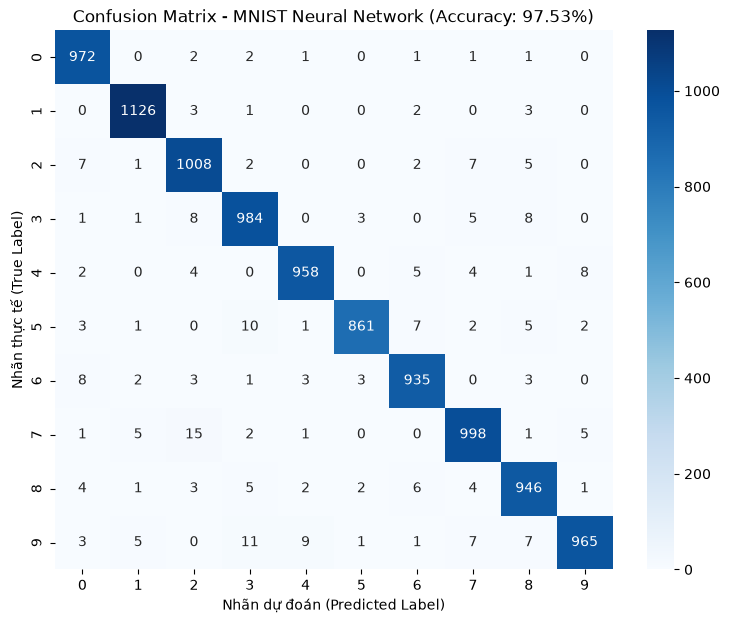

In [14]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu l) Hiển thị confusion matrix bằng heat map
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(test_labels, y_pred)

plt.figure(figsize=(9, 7))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.title(f"Confusion Matrix - MNIST Neural Network (Accuracy: {test_acc*100:.2f}%)")
plt.xlabel("Nhãn dự đoán (Predicted Label)")
plt.ylabel("Nhãn thực tế (True Label)")
plt.show()


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT


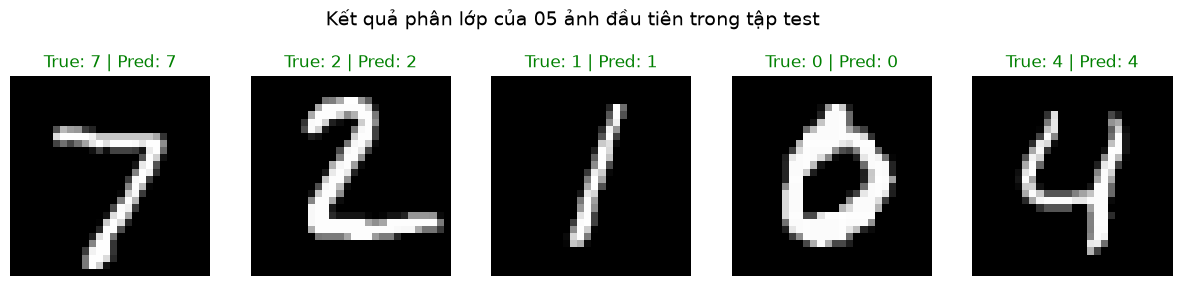

Ảnh 1: Nhãn thực tế = 7 | Nhãn dự đoán = 7 | Kết quả: CHÍNH XÁC
Ảnh 2: Nhãn thực tế = 2 | Nhãn dự đoán = 2 | Kết quả: CHÍNH XÁC
Ảnh 3: Nhãn thực tế = 1 | Nhãn dự đoán = 1 | Kết quả: CHÍNH XÁC
Ảnh 4: Nhãn thực tế = 0 | Nhãn dự đoán = 0 | Kết quả: CHÍNH XÁC
Ảnh 5: Nhãn thực tế = 4 | Nhãn dự đoán = 4 | Kết quả: CHÍNH XÁC


In [15]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu m) In ra kết quả phân lớp của 05 ảnh đầu tiên trong tập test
plt.figure(figsize=(15, 3))
for i in range(5):
    img = test_images[i]
    pred_label = y_pred[i]
    true_label = test_labels[i]
    
    plt.subplot(1, 5, i + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"True: {true_label} | Pred: {pred_label}", 
              color='green' if pred_label == true_label else 'red', fontsize=12)
    plt.axis('off')

plt.suptitle("Kết quả phân lớp của 05 ảnh đầu tiên trong tập test", fontsize=14, y=1.05)
plt.show()

for i in range(5):
    print(f"Ảnh {i+1}: Nhãn thực tế = {test_labels[i]} | Nhãn dự đoán = {y_pred[i]} | Kết quả: {'CHÍNH XÁC' if y_pred[i] == test_labels[i] else 'SAI'}")


Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT
Tổng số mẫu dự đoán sai trên tập test: 247 / 10000 mẫu.


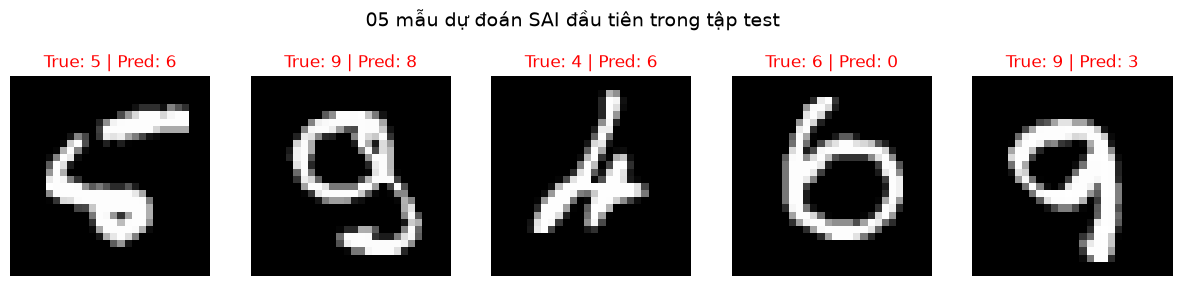

Mẫu sai 1 (Index 8): Thực tế = 5 -> Dự đoán nhầm thành = 6
Mẫu sai 2 (Index 151): Thực tế = 9 -> Dự đoán nhầm thành = 8
Mẫu sai 3 (Index 247): Thực tế = 4 -> Dự đoán nhầm thành = 6
Mẫu sai 4 (Index 259): Thực tế = 6 -> Dự đoán nhầm thành = 0
Mẫu sai 5 (Index 274): Thực tế = 9 -> Dự đoán nhầm thành = 3


In [16]:
print("Họ và tên: Phạm Hải Yến - MSSV: 6451071091 - Lớp: CQ.64.CNTT")
# Câu n) In ra 05 kết quả đầu tiên phân lớp sai so với nhãn thực tế trong tập test
# Tìm tất cả các index mà mô hình dự đoán sai
wrong_indices = np.where(y_pred != test_labels)[0]
print(f"Tổng số mẫu dự đoán sai trên tập test: {len(wrong_indices)} / {len(test_labels)} mẫu.")

plt.figure(figsize=(15, 3))
for idx, i in enumerate(wrong_indices[:5]):
    img = test_images[i]
    pred_label = y_pred[i]
    true_label = test_labels[i]
    
    plt.subplot(1, 5, idx + 1)
    plt.imshow(img, cmap='gray')
    plt.title(f"True: {true_label} | Pred: {pred_label}", color='red', fontsize=12)
    plt.axis('off')

plt.suptitle("05 mẫu dự đoán SAI đầu tiên trong tập test", fontsize=14, y=1.05)
plt.show()

for idx, i in enumerate(wrong_indices[:5]):
    print(f"Mẫu sai {idx+1} (Index {i}): Thực tế = {test_labels[i]} -> Dự đoán nhầm thành = {y_pred[i]}")
